<a href="https://colab.research.google.com/github/divyamsh8/DAV_LAB/blob/main/LABprg_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('student_dataset.csv')
print("Dataset loaded: ", 'student_dataset.csv')
display(df.head())

Dataset loaded:  student_dataset.csv


,StudyHours,Attendance,PrevMarks,Result
0,7,90,82,Pass
1,4,69,62,Fail
2,5,74,55,Pass
3,7,86,81,Pass
4,3,56,48,Fail


In [ ]:
print("dataset shape: ",df.shape)
print("\n Missing Values : ")
print(df.isnull().sum())


dataset shape:  (100, 4)

 Missing Values : 
StudyHours    0
Attendance    0
PrevMarks     0
Result        0
dtype: int64


In [ ]:
x = df[['StudyHours', 'Attendance', 'PrevMarks']]
y = df['Result']
print("Input features:")
display(x.head())
print("\nTarget variable:")
display(y.head())

Input features:


,StudyHours,Attendance,PrevMarks
0,7,90,82
1,4,69,62
2,5,74,55
3,7,86,81
4,3,56,48



Target variable:


,Result
0,Pass
1,Fail
2,Pass
3,Pass
4,Fail


In [22]:
x_tr,x_te,y_tr,y_te = train_test_split(x,y,test_size=0.2,random_state=42,stratify= y)
print("Training set shape: ",x_tr.shape)
print("Testing set shape: ",x_te.shape)

Training set shape:  (80, 3)
Testing set shape:  (20, 3)


In [24]:

tree_classifier = DecisionTreeClassifier()
tree_classifier.fit(x_tr,y_tr)
print("Decision Tree model is trained sucessfully.")

Decision Tree model is trained sucessfully.


In [30]:
y_pred=tree_classifier.predict(x_te)
comparision_df = pd.DataFrame({'Actual':y_te,'Predicted':y_pred})
display(comparision_df.head())

,Actual,Predicted
11,Pass,Pass
49,Pass,Pass
20,Pass,Pass
2,Pass,Pass
22,Fail,Fail


In [40]:

report=classification_report(y_te,y_pred,zero_division=0)
print("Classification Report:")
print(report)

Classification Report:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00        10
        Pass       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



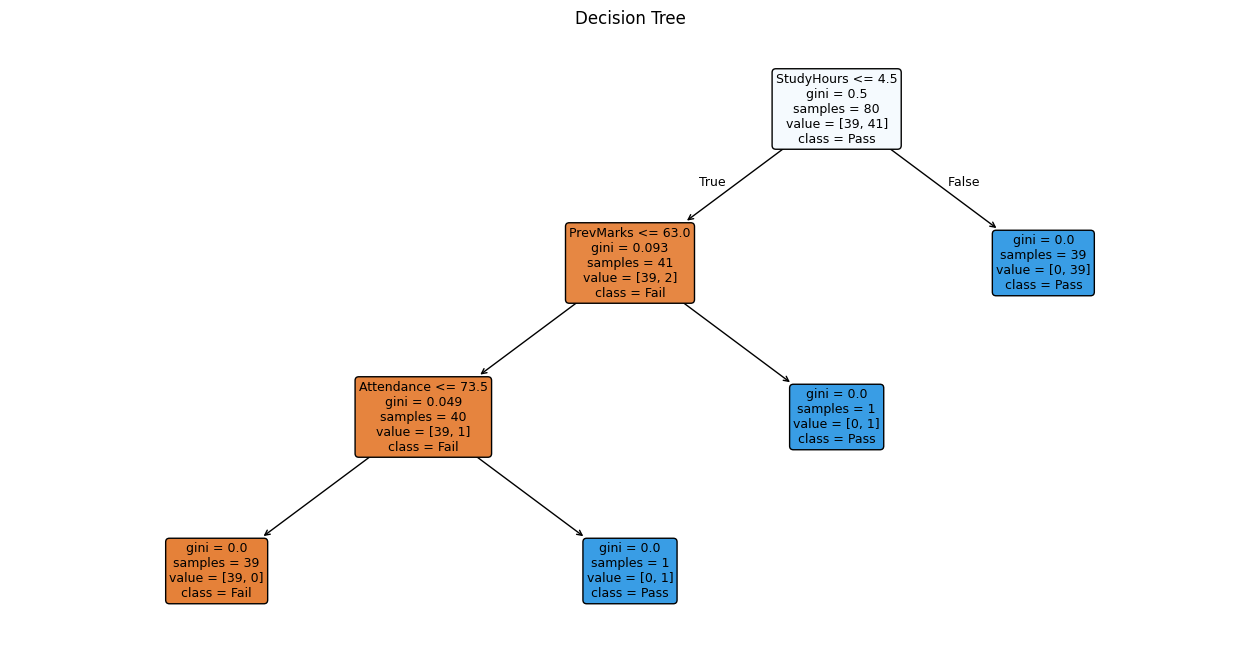

In [43]:
plt.figure(figsize=(16,8))
plot_tree(tree_classifier,filled=True,feature_names=x.columns,class_names=[str(c)for c in tree_classifier.classes_],rounded=True,fontsize=9)
plt.title("Decision Tree")
plt.show()

In [46]:
importances = tree_classifier.feature_importances_
feature_importance_df = pd.DataFrame({'Feature':x.columns,'Importance':importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance',ascending=False)
display(feature_importance_df)

,Feature,Importance
0,StudyHours,0.904819
1,Attendance,0.048780
2,PrevMarks,0.046401
